In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv(
    "sensor_readings_4.csv",
    header=None
)

df.columns = [
    'Front_Sensor',
    'Left_Sensor',
    'Right_Sensor',
    'Back_Sensor',
    'Class'
]

df.head()

,Front_Sensor,Left_Sensor,Right_Sensor,Back_Sensor,Class
0,1.687,0.445,2.332,0.429,Slight-Right-Turn
1,1.687,0.449,2.332,0.429,Slight-Right-Turn
2,1.687,0.449,2.334,0.429,Slight-Right-Turn
3,1.687,0.449,2.334,0.429,Slight-Right-Turn
4,1.687,0.449,2.334,0.429,Slight-Right-Turn


In [3]:
df.tail()

,Front_Sensor,Left_Sensor,Right_Sensor,Back_Sensor,Class
5451,1.024,0.657,1.087,1.562,Move-Forward
5452,0.894,0.649,1.071,1.085,Sharp-Right-Turn
5453,0.873,0.642,1.053,1.105,Sharp-Right-Turn
5454,0.967,0.635,1.034,1.118,Move-Forward
5455,0.854,0.628,1.016,1.168,Sharp-Right-Turn


In [4]:
df.isnull().sum()

Front_Sensor    0
Left_Sensor     0
Right_Sensor    0
Back_Sensor     0
Class           0
dtype: int64

In [5]:
df.describe()

,Front_Sensor,Left_Sensor,Right_Sensor,Back_Sensor
count,5456.000000,5456.000000,5456.000000,5456.000000
mean,1.290307,0.681269,1.881819,1.273689
std,0.626700,0.342594,0.562533,0.821750
min,0.495000,0.340000,0.836000,0.367000
25%,0.826000,0.495000,1.472000,0.788000
50%,1.089500,0.612000,1.753000,1.066500
75%,1.519500,0.753000,2.139000,1.400500
max,5.000000,5.000000,5.000000,5.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Front_Sensor  5456 non-null   float64
 1   Left_Sensor   5456 non-null   float64
 2   Right_Sensor  5456 non-null   float64
 3   Back_Sensor   5456 non-null   float64
 4   Class         5456 non-null   str    
dtypes: float64(4), str(1)
memory usage: 290.7 KB


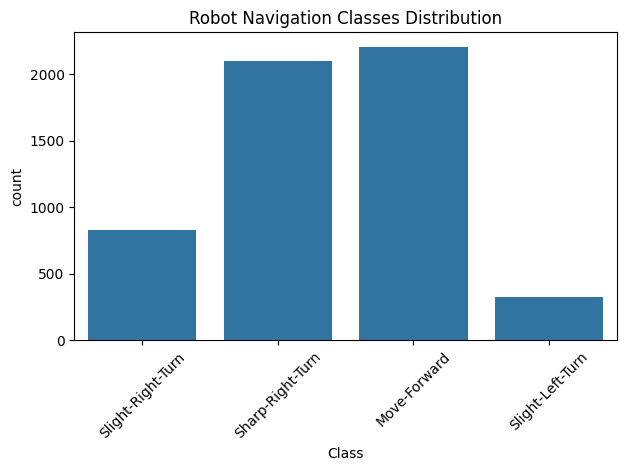

In [7]:
plt.figure(figsize=(7,4))

sns.countplot(
    x='Class',
    data=df
)

plt.xticks(rotation=45)
plt.title("Robot Navigation Classes Distribution")

plt.show()

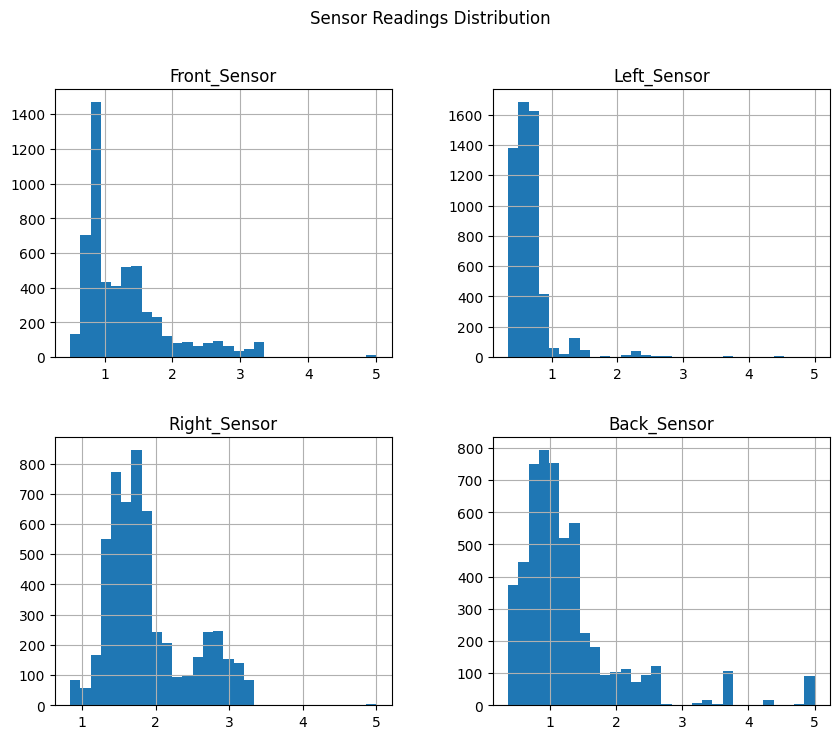

In [8]:
df[['Front_Sensor',
    'Left_Sensor',
    'Right_Sensor',
    'Back_Sensor']].hist(
        figsize=(10,8),
        bins=30
)

plt.suptitle("Sensor Readings Distribution")

plt.show()

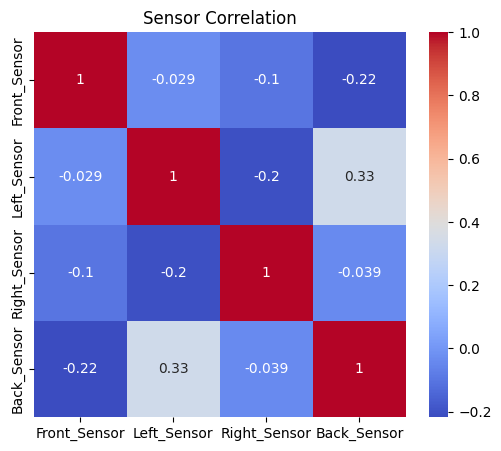

In [9]:
plt.figure(figsize=(6,5))

sns.heatmap(
    df.drop('Class',axis=1).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Sensor Correlation")

plt.show()

In [10]:
X = df.drop('Class', axis=1)

y = df['Class']

In [11]:
X.head()

,Front_Sensor,Left_Sensor,Right_Sensor,Back_Sensor
0,1.687,0.445,2.332,0.429
1,1.687,0.449,2.332,0.429
2,1.687,0.449,2.334,0.429
3,1.687,0.449,2.334,0.429
4,1.687,0.449,2.334,0.429


In [12]:
y.head()

0    Slight-Right-Turn
1    Slight-Right-Turn
2    Slight-Right-Turn
3    Slight-Right-Turn
4    Slight-Right-Turn
Name: Class, dtype: str

In [13]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

encoder.classes_

array(['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn',
       'Slight-Right-Turn'], dtype=object)

In [15]:
y[:10]

array([3, 3, 3, 3, 3, 3, 3, 3, 1, 1])

In [16]:
scaler = StandardScaler()

X = scaler.fit_transform(X)

In [18]:
X[:10]

array([[ 0.63304582, -0.68971068,  0.80034908, -1.02800827],
       [ 0.63304582, -0.67803399,  0.80034908, -1.02800827],
       [ 0.63304582, -0.67803399,  0.80390476, -1.02800827],
       [ 0.63304582, -0.67803399,  0.80390476, -1.02800827],
       [ 0.63304582, -0.67803399,  0.80390476, -1.02800827],
       [ 0.63145001, -0.68679151,  0.80390476, -1.02679125],
       [ 0.6282584 , -0.67219564,  0.79679341, -1.0243572 ],
       [ 0.62187517, -0.6663573 ,  0.7914599 , -1.01948909],
       [-0.85743807, -0.65468061,  0.78434855, -1.01218694],
       [-0.87180033, -0.64008475,  0.78079287, -1.00366775]])

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [23]:
len(X_train), len(X_test), len(y_train), len(y_test)

(4364, 1092, 4364, 1092)

In [24]:
y_pred = rf_model.predict(X_test)

In [25]:
y_pred[:10]

array([0, 3, 0, 0, 1, 0, 3, 0, 0, 0])

In [26]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.9990842490842491


In [27]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)

                   precision    recall  f1-score   support

     Move-Forward       1.00      1.00      1.00       441
 Sharp-Right-Turn       1.00      1.00      1.00       420
 Slight-Left-Turn       1.00      0.98      0.99        66
Slight-Right-Turn       1.00      1.00      1.00       165

         accuracy                           1.00      1092
        macro avg       1.00      1.00      1.00      1092
     weighted avg       1.00      1.00      1.00      1092

